<a href="https://colab.research.google.com/github/Ziruo-261/11-07_Ten_Projects_Using_Machine_Learning/blob/main/BWSI_Ten_Projects_2026_11_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BWSI | One AI Framework, Ten Projects
**Instructions:** Run the setup cell once. Then study and run the core program. Change only `PROJECT` and `METHOD`.
**Pairs:** Choose one project, compare all three methods, and explain your result.


In [1]:
# Prepared data package. Run this cell once; no uploads or external downloads needed.
import base64, io, zipfile
DATA_ARCHIVE = "..."
with zipfile.ZipFile(io.BytesIO(base64.b64decode(DATA_ARCHIVE))) as folder:
    folder.extractall("data")
print("Ready: 10 included public sample datasets.")

Ready: 10 included public sample datasets.


## The 33-line AI skeleton
The same code works for every dataset. Each numbered line is explained in the instructor guide. No extra libraries or downloads beyond those already available in Google Colab are required.


Project: medical
Method: tree
Accuracy: 93.71%
First prediction: 1 Actual: 1


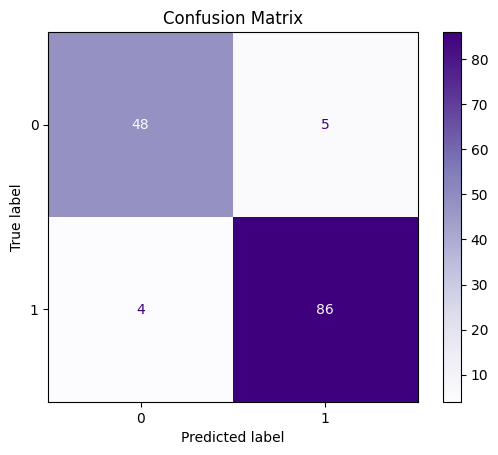

In [32]:
import pandas as pd # allows for data to be organized, cleaned, and analyzed
from sklearn.model_selection import train_test_split # divides dataset into training data and testing data
from sklearn.preprocessing import StandardScaler # scale data down to compare them, since sometimes data is not initially comparable
from sklearn.neighbors import KNeighborsClassifier # use the closest neighbors to classify a new set of data, Example: If trying to classify a new fruit, two of data points are apples and one is a strawberry, classify as apple
from sklearn.tree import DecisionTreeClassifier # uses a decision tree to classify new set of data, brances out to classify different data
from sklearn.ensemble import RandomForestClassifier # creates multiple decision trees, whichever output is most common becomes final answer
from sklearn.metrics import accuracy_score # tells what percentage of predictions are correct
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
PROJECT = "medical" # tells which type of project you are doing
METHOD = "tree" # tells which type of classifier you are using
data = pd.read_csv("data/" + PROJECT + ".csv") # csv is a text file that stores tabular data, in rows or columns, loading data in that certain format
X = data.drop(columns=["answer"]) # organizing input data so only inital data is shown in X
y = data["answer"] #putting the prediction answer as Y
ordered = PROJECT in ["solar", "economy"] # Boolean, if project in solar or economy, data has to be ordered in a certain way
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42,
    shuffle=not ordered, stratify=None if ordered else y
) #splitting up the data into several parts
# X_train are the data values used to train the machine learning
# Y_train is the output values of these training data set
# X_test are the values for testing the newly learned machine learning
# Y_test are the final predictions
#75 percent used for training, 25 percent used for actual test
# start with 42 as random data number
models = {
    "neighbors": KNeighborsClassifier(n_neighbors=5), #looks at five closest data points to make a prediction
    "tree": DecisionTreeClassifier(max_depth=5, random_state=42),# tree has a maximum depth of 5, chooses 42 to start randomly
    "forest": RandomForestClassifier(n_estimators=100, random_state=45) #creates a hundred decision trees, chooses 42 to start randomly
} #saying that model used could be any of these
model = models[METHOD] #picking which model to use
scaler = StandardScaler() # saying you can write scaler instead of StandardScaler
X_train = scaler.fit_transform(X_train) #adjusts data to have similar scale so they are comparable
X_test = scaler.transform(X_test) #adjusts data to have similar scale so they are comparable
model.fit(X_train, y_train) # trains the training data
predictions = model.predict(X_test) # stores the predictions made from the testing models
accuracy = accuracy_score(y_test, predictions) # compares predections to actual correct answers
print("Project:", PROJECT) #prints what project was chosen
print("Method:", METHOD) # displays what method was used
print("Accuracy:", f"{accuracy:.2%}") # displays the accuracy to a chosen number of decimal places
print("First prediction:", predictions[0], "Actual:", y_test.iloc[0]) #displays results for the first prediciton
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predictions) #calculates the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix= cm) #plotting confusion matrix
disp.plot(cmap="Purples")
plt.title("Confusion Matrix")
plt.show()



## Student mission
1. Select one of the 10 `PROJECT` names. 2. Run `neighbors`, `tree`, and `forest`. 3. Record three accuracies. 4. Change one hyperparameter and explain what happened. 5. Share one ethical or data-quality limitation.
**Note:** Accuracy is not sufficient for medical, educational, or economic decisions.


In [5]:
# Optional extension: test a prediction on a single unseen example
print("Input values:", X_test[0])
print("AI prediction:", model.predict(X_test[:1])[0])


Input values: [-0.64703118 -0.46067897 -0.67715792 -0.63955449  0.31604669 -0.9288439
 -0.81740728 -0.844301   -0.37840281 -0.71499789 -0.83201143  1.29954684
 -0.9879722  -0.60726753  0.30202715 -0.91784212 -0.52123237 -0.89877218
  1.39550402 -0.65388421 -0.76261101  0.125414   -0.82006981 -0.69286665
  0.13424424 -0.97578874 -0.88912855 -1.0719986   0.4840359  -0.99923347]
AI prediction: 1
